# PRÁCTICA 3 MACHINE LEARNING

In [66]:
#!pip install shap

In [68]:
#!pip install sklearn

In [ ]:
%matplotlib inline

# First downgrade NumPy to a compatible version for Numba
!pip install numpy==1.21.0 --force-reinstall

# Wait for NumPy installation to complete
import time
time.sleep(5)

# Restart the kernel to ensure the correct NumPy version is loaded
# Note: You'll need to manually restart the kernel after running this cell
# and then run the remaining code

# After restarting, run these imports
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

# Now install lime
!pip install lime

#Módulos de interpretabilidad
import lime
import lime.lime_tabular
import shap

#Módulos de modelos
from sklearn import linear_model
from sklearn import model_selection
from sklearn import metrics
from sklearn import ensemble
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

#Módulos de evaluación de modelos
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.metrics import f1_score, precision_score, recall_score

# Para que se muestren todas las columnas del DataFrame
pd.options.display.max_columns = 100

## EDA

### Análisis Univariante

In [105]:
df = pd.read_csv("C:/Users/carte/OneDrive/Documentos/MASTER IA/MACHINE LEARNING/PRACTICA/PRACTICA 3/data/BostonHousing.csv")
df.head(5)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [106]:
#identificación de nulos
print(df.isnull().sum())

crim       0
zn         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
b          0
lstat      0
medv       0
dtype: int64


In [107]:
#identificamos de que tipo son las variables
df.dtypes

crim       float64
zn         float64
indus      float64
chas         int64
nox        float64
rm         float64
age        float64
dis        float64
rad          int64
tax          int64
ptratio    float64
b          float64
lstat      float64
medv       float64
dtype: object

#### Variables numéricas

In [139]:
#sacamos la variable binaria CHAS
numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns.drop('chas').tolist()
numerical_columns

['crim',
 'zn',
 'indus',
 'nox',
 'rm',
 'age',
 'dis',
 'rad',
 'tax',
 'ptratio',
 'b',
 'lstat',
 'medv']

In [109]:
df[numerical_columns].describe().round(2)

,crim,zn,indus,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00,506.00
mean,3.61,11.36,11.14,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65,22.53
std,8.60,23.32,6.86,0.12,0.70,28.15,2.11,8.71,168.54,2.16,91.29,7.14,9.20
min,0.01,0.00,0.46,0.38,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
25%,0.08,0.00,5.19,0.45,5.89,45.02,2.10,4.00,279.00,17.40,375.38,6.95,17.02
50%,0.26,0.00,9.69,0.54,6.21,77.50,3.21,5.00,330.00,19.05,391.44,11.36,21.20
75%,3.68,12.50,18.10,0.62,6.62,94.07,5.19,24.00,666.00,20.20,396.22,16.96,25.00
max,88.98,100.00,27.74,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


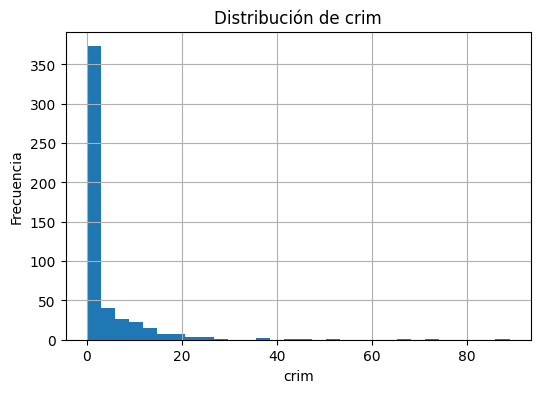

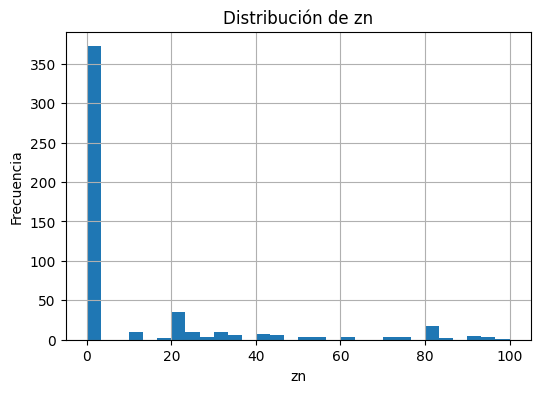

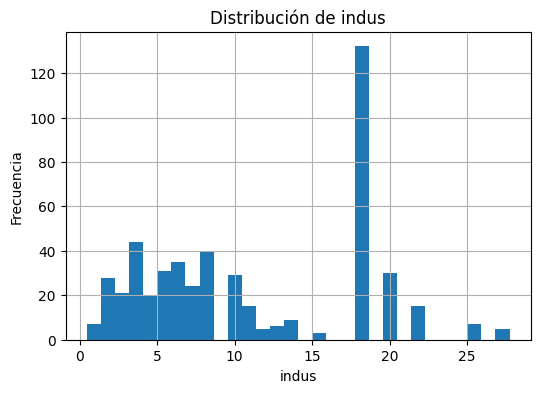

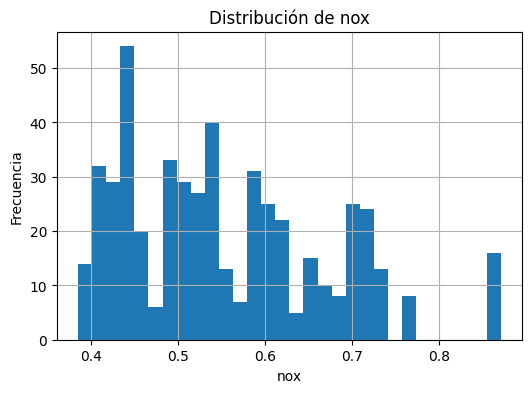

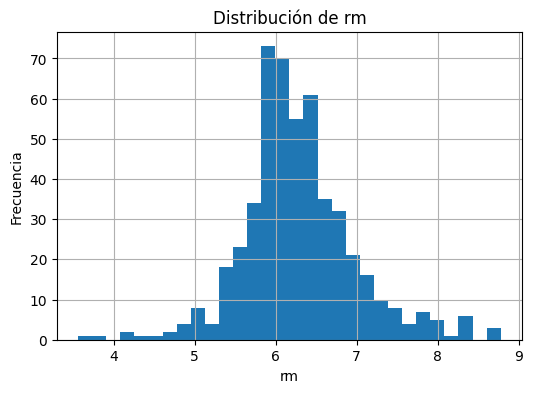

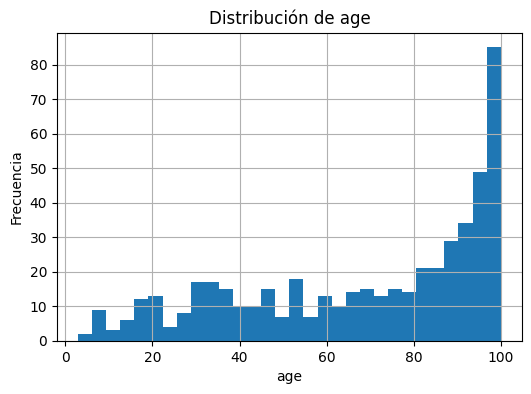

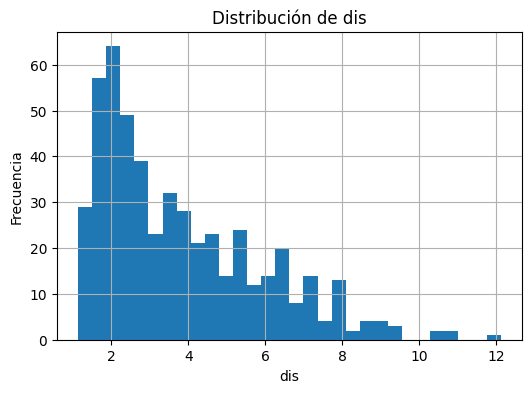

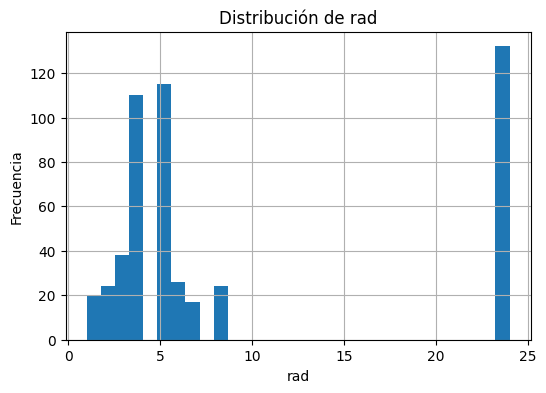

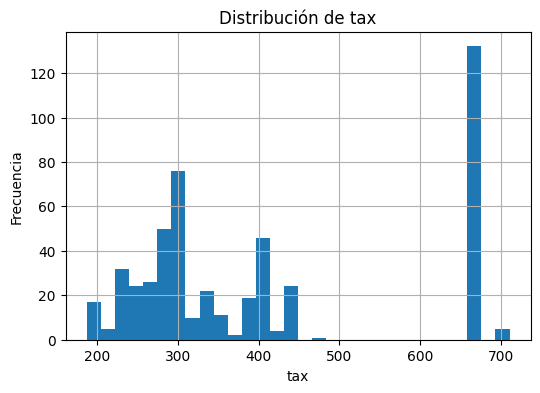

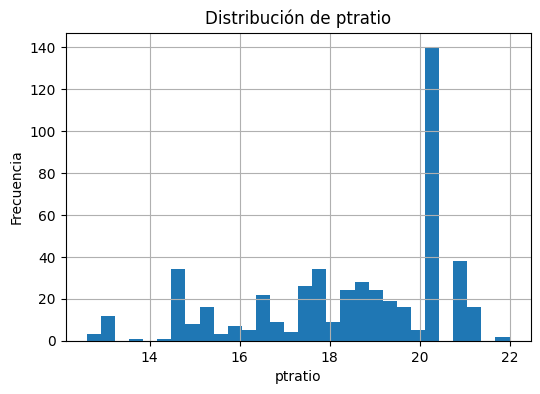

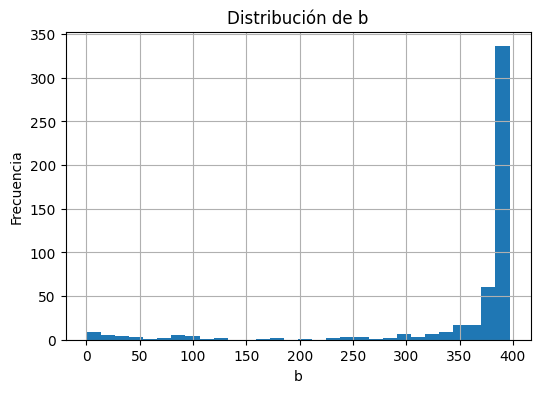

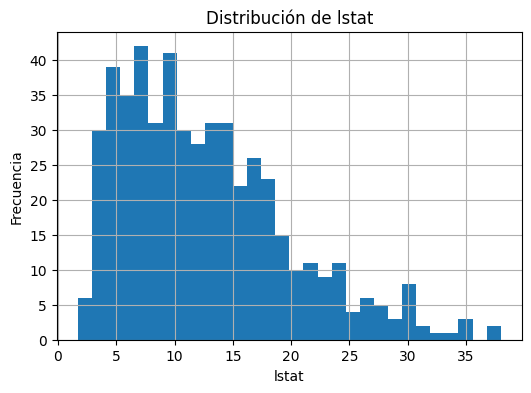

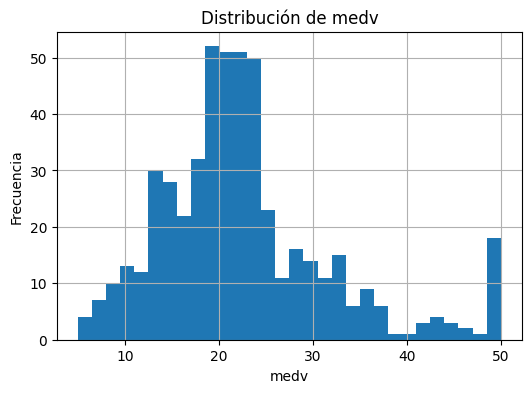

In [110]:
#hacemos el histograma
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    df[col].hist(bins=30)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

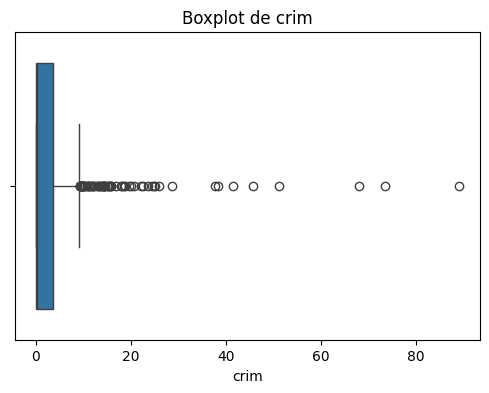

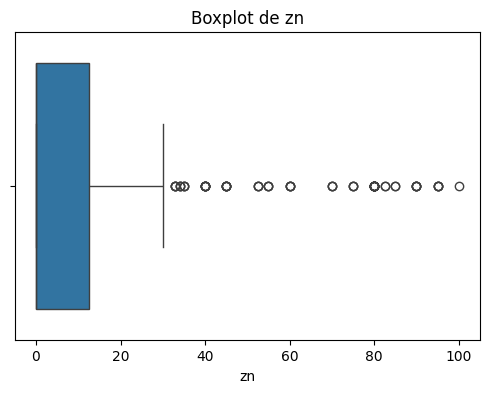

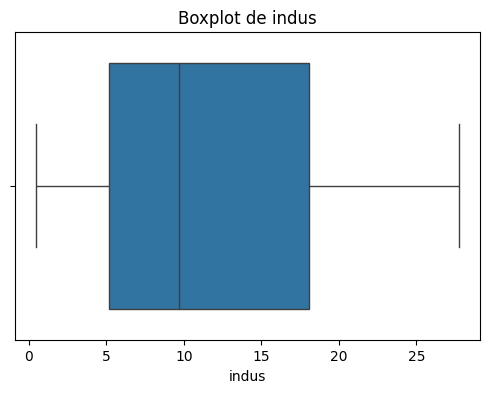

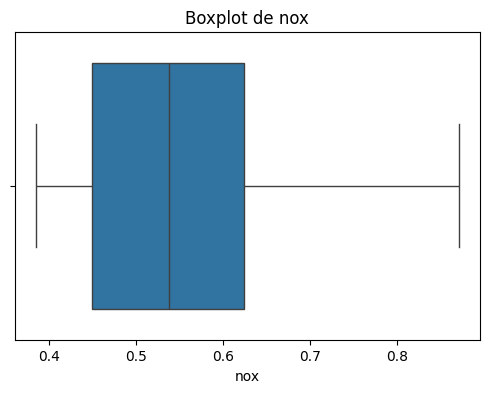

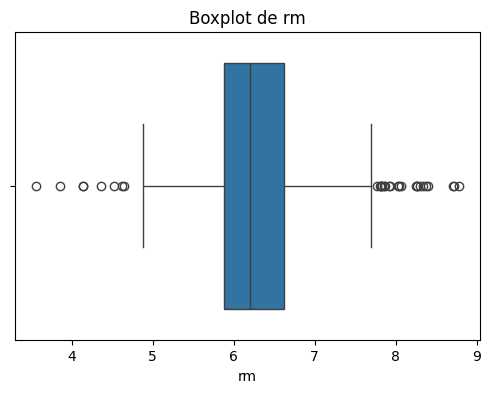

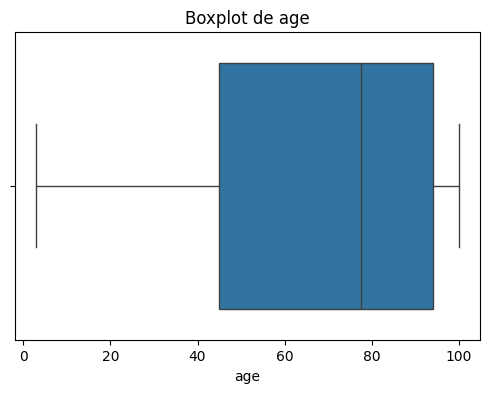

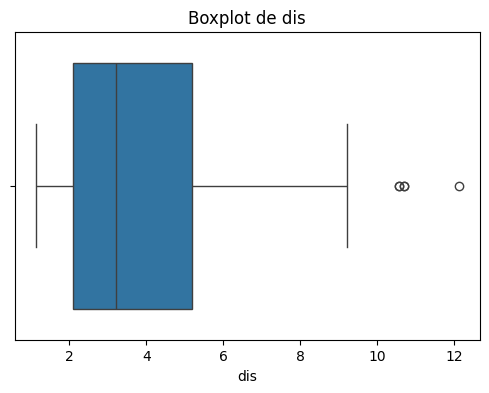

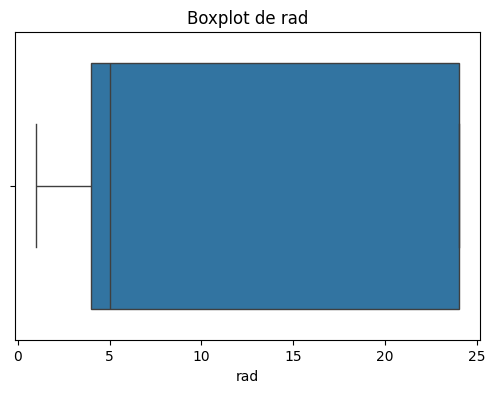

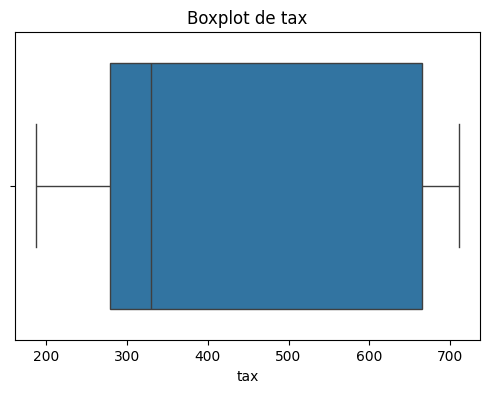

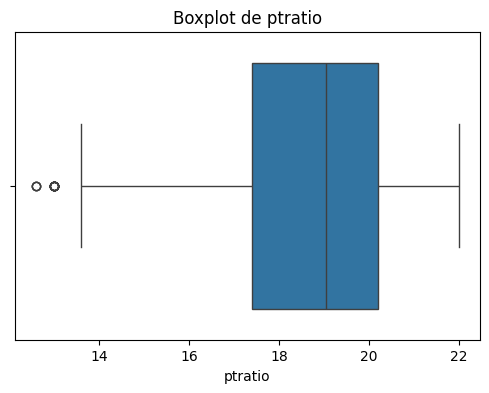

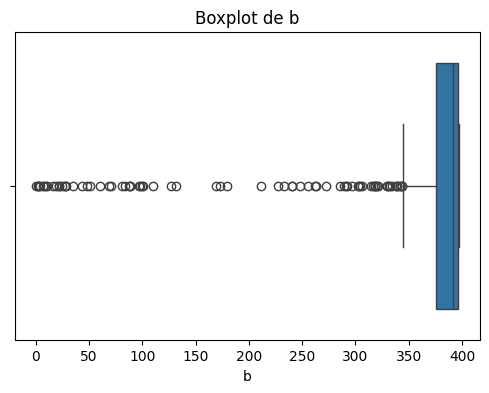

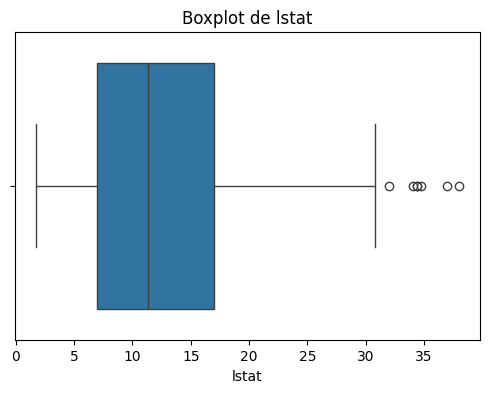

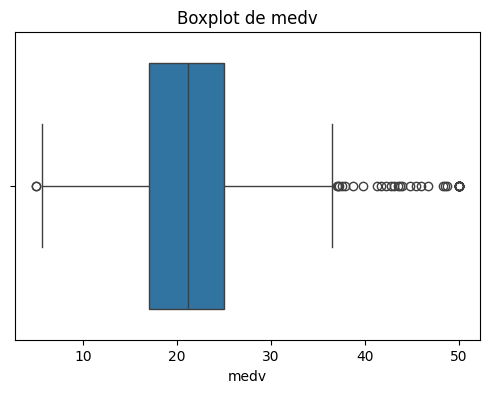

In [111]:
#hacemos los boxplots
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

El análisis univariante muestra que muchas variables presentan distribuciones asimétricas y presencia de algunos outliers, especialmente en variables como CRIM, ZN, DIS o LSTAT. Otras variables, como RM o PTRATIO, presentan distribuciones más equilibradas. Además, se observa que varias variables tienen gran variabilidad entre barrios, lo que sugiere diferencias socioeconómicas y urbanísticas importantes en la ciudad de Boston. Estas características pueden influir en el precio de las viviendas (MEDV).

#### Variable Categórica

In [140]:
#solo hay una variable catégorica
categorical_columns = ['chas']
categorical_columns

['chas']

In [114]:
#conteo de valores
df['chas'].value_counts()

chas
0    471
1     35
Name: count, dtype: int64

In [115]:
#propoción de valores
df['chas'].value_counts(normalize=True)

chas
0    0.93083
1    0.06917
Name: proportion, dtype: float64

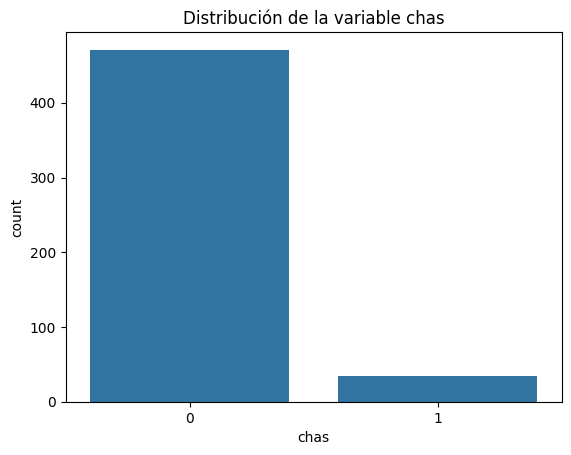

In [116]:
#hacemos el barplot

sns.countplot(x='chas', data=df)
plt.title("Distribución de la variable chas")
plt.show()

El gráfico de barras muestra que la mayoría de las observaciones del dataset tienen chas = 0, lo que indica que la mayor parte de las viviendas no están situadas junto al río Charles. En cambio, solo una pequeña proporción de viviendas presenta chas = 1, por lo que vivir cerca del río es una característica poco frecuente dentro del conjunto de datos.

### Análisis Multivariante

#### Numérica vs Numérica

In [117]:
#vemos las correlaciones entre variables
corr_numerical = df[numerical_columns].corr()
corr_numerical.round(3)

,crim,zn,indus,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
crim,1.000,-0.200,0.407,0.421,-0.219,0.353,-0.380,0.626,0.583,0.290,-0.385,0.456,-0.388
zn,-0.200,1.000,-0.534,-0.517,0.312,-0.570,0.664,-0.312,-0.315,-0.392,0.176,-0.413,0.360
indus,0.407,-0.534,1.000,0.764,-0.392,0.645,-0.708,0.595,0.721,0.383,-0.357,0.604,-0.484
nox,0.421,-0.517,0.764,1.000,-0.302,0.731,-0.769,0.611,0.668,0.189,-0.380,0.591,-0.427
rm,-0.219,0.312,-0.392,-0.302,1.000,-0.240,0.205,-0.210,-0.292,-0.356,0.128,-0.614,0.695
age,0.353,-0.570,0.645,0.731,-0.240,1.000,-0.748,0.456,0.506,0.262,-0.274,0.602,-0.377
dis,-0.380,0.664,-0.708,-0.769,0.205,-0.748,1.000,-0.495,-0.534,-0.232,0.292,-0.497,0.250
rad,0.626,-0.312,0.595,0.611,-0.210,0.456,-0.495,1.000,0.910,0.465,-0.444,0.489,-0.382
tax,0.583,-0.315,0.721,0.668,-0.292,0.506,-0.534,0.910,1.000,0.461,-0.442,0.544,-0.469
ptratio,0.290,-0.392,0.383,0.189,-0.356,0.262,-0.232,0.465,0.461,1.000,-0.177,0.374,-0.508


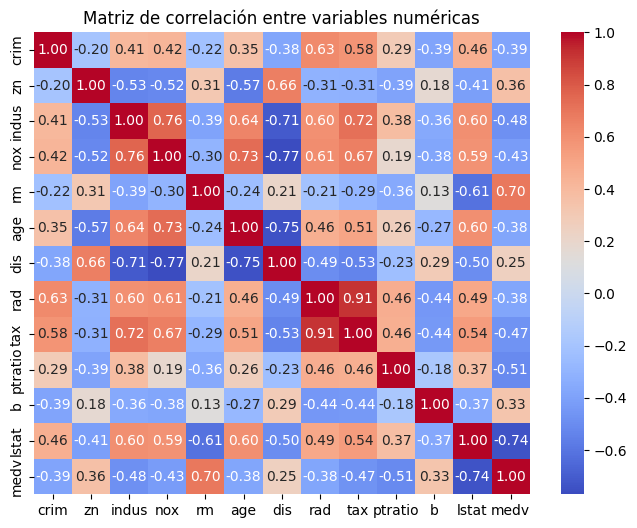

In [118]:
#hacemos el heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_numerical,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Matriz de correlación entre variables numéricas")
plt.show()

El análisis de correlaciones muestra que algunas variables presentan relaciones significativas con el precio medio de las viviendas (medv). En particular, RM presenta una correlación positiva fuerte, indicando que las viviendas con mayor número de habitaciones tienden a tener precios más elevados. Por el contrario, LSTAT muestra una correlación negativa fuerte, lo que sugiere que los barrios con mayor porcentaje de población de bajo estatus socioeconómico presentan precios de vivienda más bajos.

Asimismo, hay algunas variables que tienen alta relación entre sí, especialmente RAD y TAX, ya que las zonas con mayor accesibilidad a autopistas suelen tener tasas de impuestos más altas. Otra correlación relevante aparece entre NOX e INDUS, ya que las zonas con mayor actividad industrial tienden a presentar mayores niveles de contaminación ambiental. También suele observarse una correlación negativa entre DIS y NOX; cuando aumenta la distancia a los centros de empleo, los niveles de contaminación tienden a disminuir.

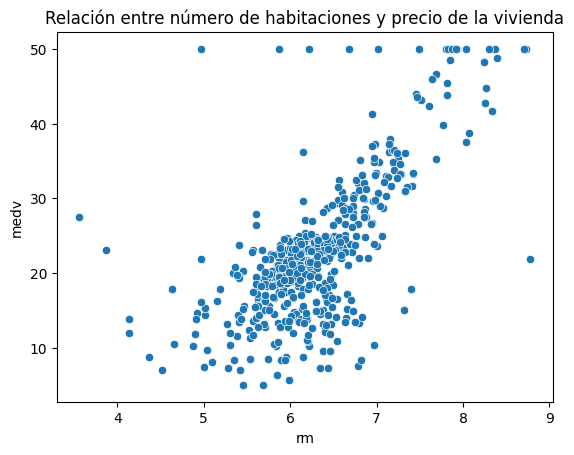

In [119]:
#scatterplot de las variables con mas relacion con la variable objetivo
sns.scatterplot(x='rm', y='medv', data=df)
plt.title("Relación entre número de habitaciones y precio de la vivienda")
plt.show()

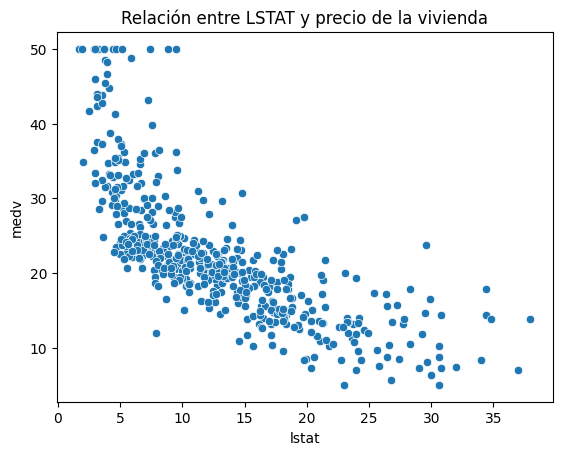

In [120]:
sns.scatterplot(x='lstat', y='medv', data=df)
plt.title("Relación entre LSTAT y precio de la vivienda")
plt.show()

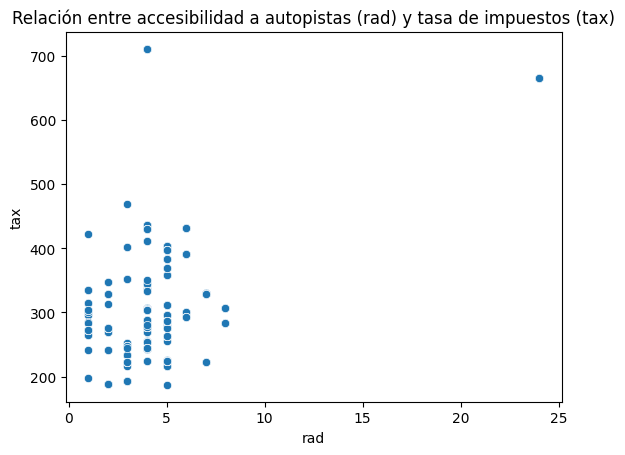

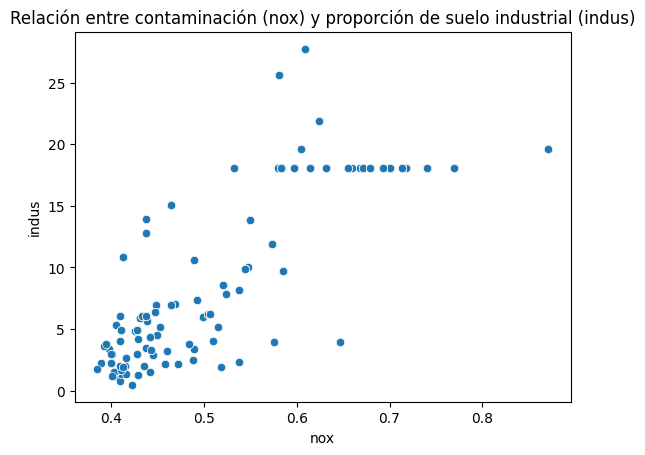

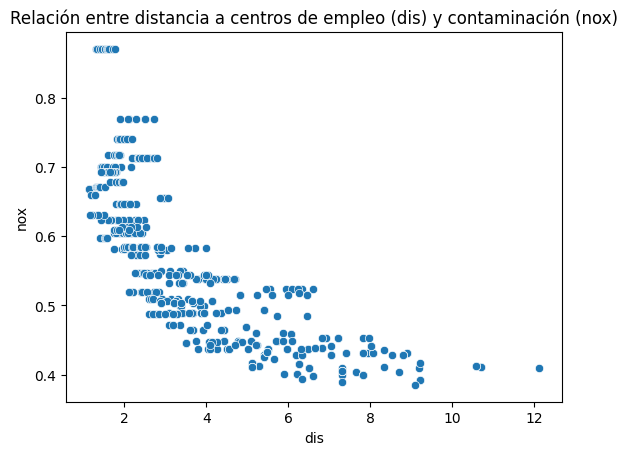

In [121]:
#scatterplot de variables con alta relacion entre si

# RAD vs TAX
sns.scatterplot(x='rad', y='tax', data=df)
plt.title("Relación entre accesibilidad a autopistas (rad) y tasa de impuestos (tax)")
plt.show()

# NOX vs INDUS
sns.scatterplot(x='nox', y='indus', data=df)
plt.title("Relación entre contaminación (nox) y proporción de suelo industrial (indus)")
plt.show()

# DIS vs NOX
sns.scatterplot(x='dis', y='nox', data=df)
plt.title("Relación entre distancia a centros de empleo (dis) y contaminación (nox)")
plt.show()

#### Numérica vs Categórica

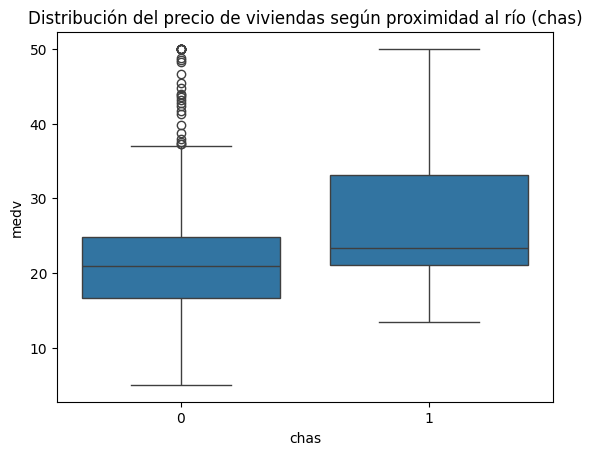

In [122]:
#hacemos boxplot y barplot de chas vs medv

sns.boxplot(x='chas', y='medv', data=df)
plt.title("Distribución del precio de viviendas según proximidad al río (chas)")
plt.show()

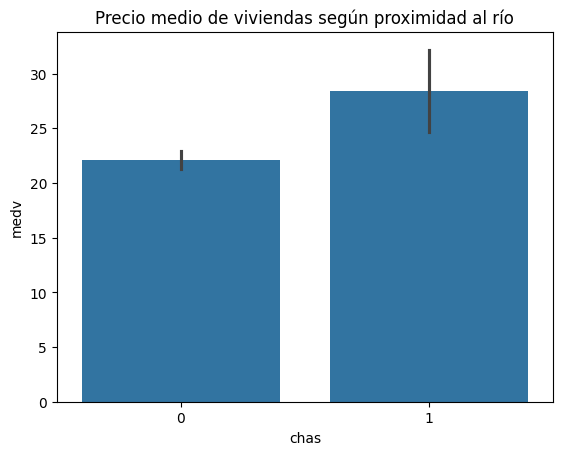

In [123]:
sns.barplot(x='chas', y='medv', data=df)
plt.title("Precio medio de viviendas según proximidad al río")
plt.show()

El análisis entre la variable categórica chas y la variable numérica medv muestra que las viviendas situadas cerca del río Charles tienden a presentar precios medios más elevados que aquellas que no se encuentran próximas al río

## MODELADO

In [124]:
#Separar variables predictoras y variable objetivo
X = df.drop('medv', axis=1)
y = df['medv']

In [125]:
#Dividir datos en entrenamiento y test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [126]:
#Entrenar al modelo
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(random_state=42)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [127]:
y_pred = rf_model.predict(X_test)

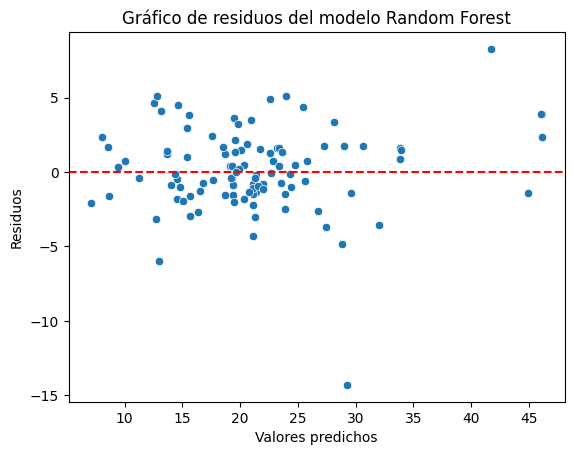

In [128]:
#hacemos el gradico de residuos
residuos = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuos)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Gráfico de residuos del modelo Random Forest")
plt.show()

El gráfico de residuos muestra que los errores del modelo se distribuyen alrededor de cero sin presentar un patrón claro, lo que sugiere que el modelo de Random Forest captura adecuadamente la relación entre las variables del dataset y el precio de las viviendas. No obstante, se observa cierta dispersión en algunos puntos, lo que indica la presencia de errores de predicción en determinadas observaciones.

In [129]:
#evaluamos el modelo
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 2.0395392156862746
MSE: 7.901513892156864
RMSE: 2.8109631609391226
R2: 0.8922527442109116


El valor de MAE es relativamente bajo, lo que indica que el modelo realiza predicciones bastante precisas. A su vez, el valor de MSE sugiere que el modelo no presenta errores extremadamente grandes de forma frecuente, lo que indica un rendimiento adecuado, mientras que el RMSE es relativamente bajo en comparación con el rango de precios del dataset, lo que indica que el modelo tiene una buena capacidad predictiva. Por último, el valor de R2 es muy alto, lo que indica que el modelo captura de forma eficaz la relación entre las variables del dataset y el precio de las viviendas.

## INTERPRETABILIDAD 

### Interpretabilidad global

In [130]:
#sacamos las variables más importantes
import pandas as pd

importancias = pd.DataFrame({
    'variable': X_train.columns,
    'importancia': rf_model.feature_importances_
}).sort_values(by='importancia', ascending=False)

print(importancias)

   variable  importancia
5        rm     0.503845
12    lstat     0.309509
7       dis     0.060549
0      crim     0.038062
10  ptratio     0.016313
9       tax     0.015661
4       nox     0.015544
6       age     0.013840
11        b     0.012154
2     indus     0.007953
8       rad     0.003811
1        zn     0.001756
3      chas     0.001004


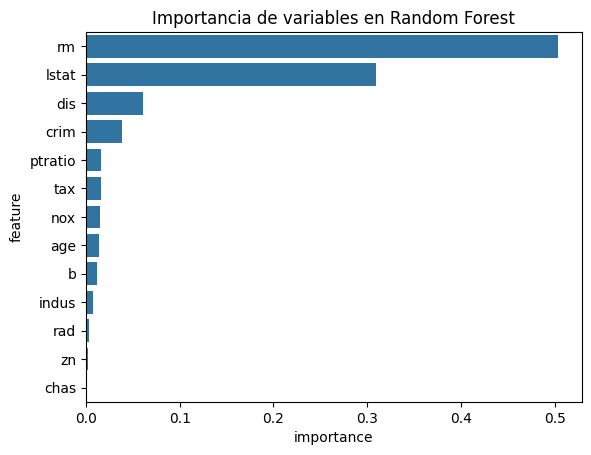

In [131]:
#grafico de las variables mas importantes
importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': importances
}).sort_values(by='importance', ascending=False)

sns.barplot(x='importance', y='feature', data=feature_importance)
plt.title("Importancia de variables en Random Forest")
plt.show()

El análisis de la importancia de variables muestra que algunas características tienen mayor influencia en la predicción del precio de las viviendas. En particular, variables como LSTAT y RM suelen presentar una mayor importancia, lo que indica que factores socioeconómicos y estructurales de las viviendas influyen significativamente en su valor. Otras variables también contribuyen al modelo, aunque con menor peso, reflejando que el precio de las viviendas depende de múltiples factores del entorno urbano.

### Interpretabilidad local

In [132]:
#Inicializamos el objeto explainer para regresión
explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data = X_train.values,
    feature_names = X_train.columns,
    mode = 'regression'
)

In [133]:
#elegimos una instacia
i=3

In [134]:
exp = explainer.explain_instance(
    X_test.iloc[i].values,
    rf_model.predict,
    num_features=10
)

C:\Users\carte\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [135]:
exp.show_in_notebook()

In [136]:
i=0

In [137]:
exp = explainer.explain_instance(
    X_test.iloc[i].values,
    rf_model.predict,
    num_features=10
)

C:\Users\carte\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [138]:
exp.show_in_notebook()

Las barras azules representan las variables que contribuyen a aumentar la predicción del precio de la vivienda, mientras que las barras naranjas indican aquellas que reducen la predicción. La longitud de cada barra refleja la magnitud de la influencia de cada variable en la predicción del modelo.

Los resultados muestran que variables como RM y LSTAT tienen una influencia significativa en la predicción del precio de la vivienda, confirmando lo observado previamente en el análisis de importancia de variables.